# 04 - Prepare the target annotation pilot

**Run on your HPC in the existing `oct_nfl` kernel. No GPU job is required.**

This step prepares original-resolution images and blank reference templates for expert annotation. It does not create labels, train DINO, or change the existing model.

Copy the complete toolkit folder to `~/OCT-RTFL/tools/OCT-RTFL-annotation-pilot/` before running. The 20 previously reviewed target cases remain **development examples**, not an independent test cohort.


## Cell 1 - Locate the project and toolkit

This cell loads the preparation functions. Keep the source and protocol together in the copied directory. Do not change your working nnU-Net environment just for this preparation step.


In [1]:
from pathlib import Path
import importlib.util
import json

ROOT = Path.home() / "OCT-RTFL"
TOOLKIT = ROOT / "tools/OCT-RTFL-annotation-pilot"
SCRIPT = TOOLKIT / "src/prepare_target_annotation.py"
assert SCRIPT.is_file(), f"Copy the full toolkit first: {SCRIPT}"
spec = importlib.util.spec_from_file_location("annotation_prep", SCRIPT)
prep = importlib.util.module_from_spec(spec)
spec.loader.exec_module(prep)
print("Project:", ROOT)
print("Toolkit:", TOOLKIT)


Project: /home/btech10862.24/OCT-RTFL
Toolkit: /home/btech10862.24/OCT-RTFL/tools/OCT-RTFL-annotation-pilot


## Cell 2 - Audit the pilot and available metadata

Reads the 20 BMPs and confirms that their palette-decoded grayscale matches the existing native PNGs. Also checks saved source hashes. A mismatch is a reason to inspect the exact file/schema; do not bypass the check.

The `INT` output is only a filename inventory. It does not establish that the files contain labels or known subject identities. Avoid sharing identifiable filenames publicly.


In [2]:
audit = prep.audit_project(ROOT)
summary = {k: v for k, v in audit.items() if k != "cases"}
print(json.dumps(summary, indent=2))

import pandas as pd
display(pd.DataFrame(audit["cases"])[["case_id", "width", "height"]])
print("All source hashes and native decoded images verified.")
print("Patient/eye/volume groups remain unverified; no split created.")


{
  "schema_version": 1,
  "created_utc": "2026-10-11T11:08:03.517587+00:00",
  "project_root": "/home/btech10862.24/OCT-RTFL",
  "source_manifest": "/home/btech10862.24/OCT-RTFL/outputs/target_pilot/pilot_export_manifest.csv",
  "source_manifest_sha256": "e66547b7c00259e17a12fa8db97fb9df9c02e25321c001f13706193aa3c5ddc6",
  "verified_cases": 20,
  "native_profiles_height_x_width": {
    "800x1004": 20
  },
  "bmp_file_count": 1025,
  "metadata_inventory": {
    "INT_present": true,
    "INT_file_count": 1277,
    "INT_suffix_counts": {
      ".bmp": 1277
    },
    "INT_examples_relative_to_target": [
      "INT/INT_00001.bmp",
      "INT/INT_00002.bmp",
      "INT/INT_00003.bmp",
      "INT/INT_00004.bmp",
      "INT/INT_00005.bmp",
      "INT/INT_00006.bmp",
      "INT/INT_00007.bmp",
      "INT/INT_00008.bmp",
      "INT/INT_00009.bmp",
      "INT/INT_00010.bmp",
      "INT/INT_00011.bmp",
      "INT/INT_00012.bmp"
    ],
    "note": "Filenames only; file contents and patient groupi

,case_id,width,height
0,target_00512,1004,800
1,target_00000,1004,800
2,target_00056,1004,800
3,target_00113,1004,800
4,target_00170,1004,800
5,target_00227,1004,800
6,target_00284,1004,800
7,target_00341,1004,800
8,target_00397,1004,800
9,target_00454,1004,800


All source hashes and native decoded images verified.
Patient/eye/volume groups remain unverified; no split created.


## Cell 3 - Review original images, without model overlays

Shows one comparatively stable example and several earlier failure examples. These four are a sanity preview, not a representative test set. Check that the scans are the intended originals with normal orientation and full field of view.


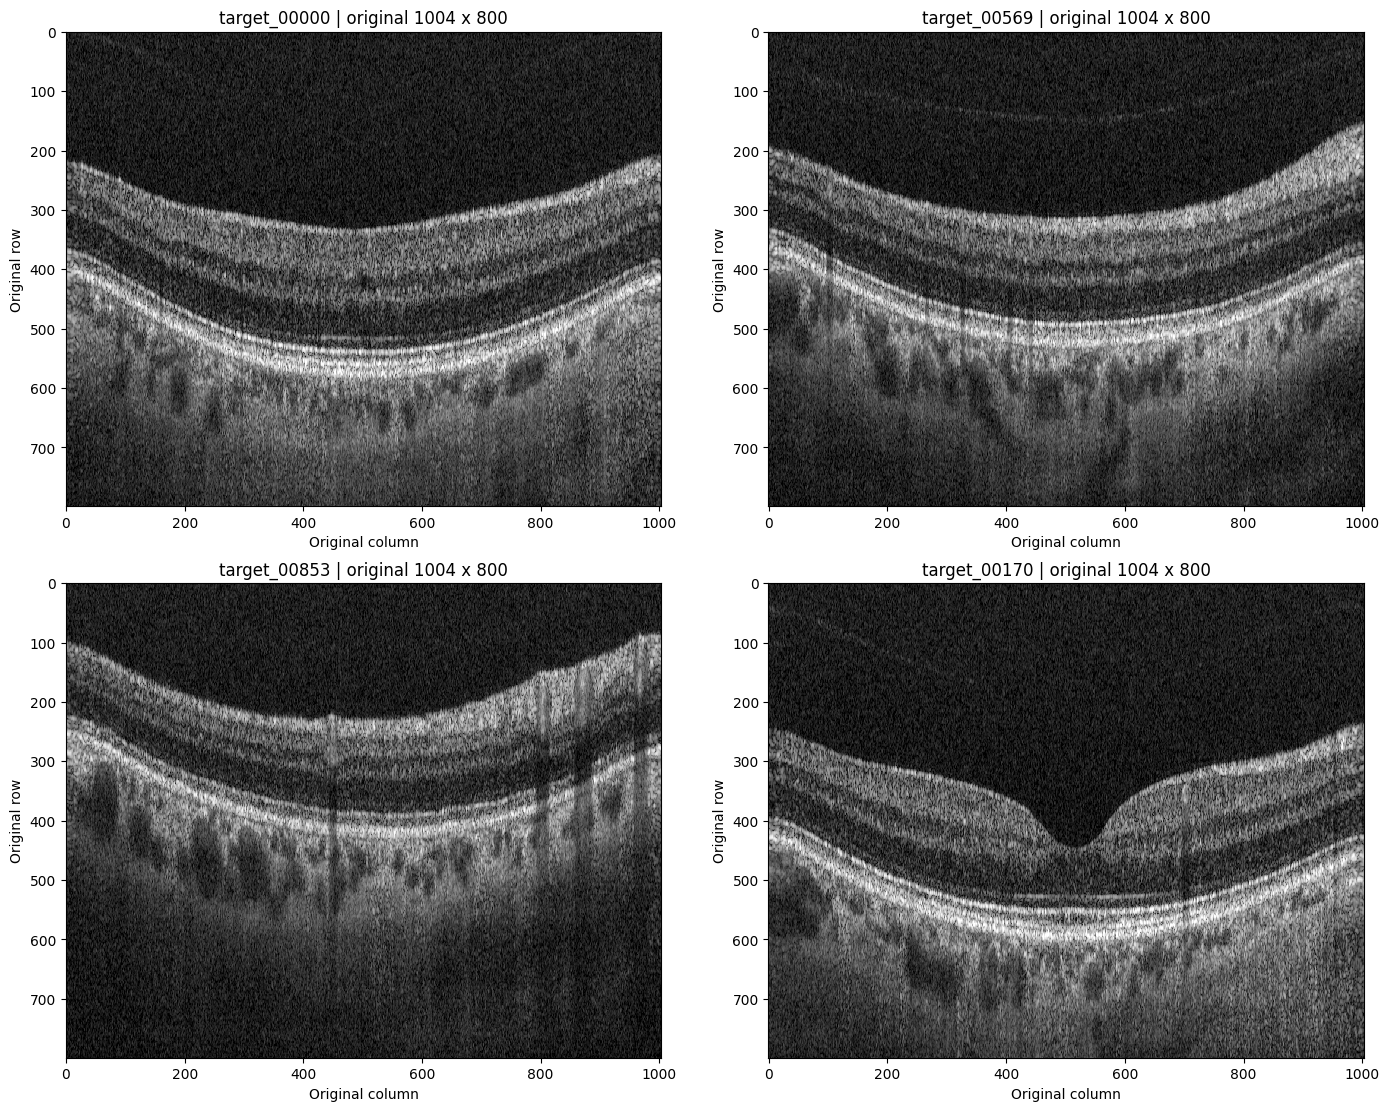

In [3]:
import matplotlib.pyplot as plt

lookup = {r["case_id"]: r for r in audit["cases"]}
preview_ids = ["target_00000", "target_00569", "target_00853", "target_00170"]
fig, axes = plt.subplots(2, 2, figsize=(14, 11), constrained_layout=True)
for ax, cid in zip(axes.ravel(), preview_ids):
    gray = prep.decode_gray(Path(lookup[cid]["source_path"]))
    ax.imshow(gray, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(f"{cid} | original {gray.width} x {gray.height}")
    ax.set_xlabel("Original column")
    ax.set_ylabel("Original row")
plt.show()


## Cell 4 - Prepare the expert-review pack

Creates a new `outputs/target_annotation/pilot_v1` directory. Existing directories are preserved and never overwritten. Each blank boundary CSV has one original-image column per row; blanks are **unreviewed**, not zero thickness.

No masks or predictions are copied into the reference images. Use an expert's annotation tool to trace interfaces and later convert its export to the CSV convention. Do not manually invent a curve from a model overlay.


In [4]:
result = prep.prepare_pack(ROOT)
PACK = Path(result["output"])
print(json.dumps(result, indent=2))
print((PACK / "PACK_STATUS.json").read_text())
print("Read the annotation instructions:", PACK / "ANNOTATION_PROTOCOL.md")


{
  "output": "/home/btech10862.24/OCT-RTFL/outputs/target_annotation/pilot_v1",
  "images": 20,
  "status": "awaiting_expert_annotation"
}
{
  "status": "awaiting_expert_annotation",
  "ground_truth_available": false,
  "model_predictions_included": false,
  "images": 20,
  "coordinate_system": "original image; zero-based column and row; row increases downward",
  "boundary_templates": "Blank exchange-format templates; not training masks or expert labels.",
  "split_status": "No train/validation/test split created. Existing 20 cases are development-only."
}
Read the annotation instructions: /home/btech10862.24/OCT-RTFL/outputs/target_annotation/pilot_v1/ANNOTATION_PROTOCOL.md


## Cell 5 - Confirm what has and has not been created

`grouping_to_complete.csv` must be filled from verified metadata. Leave unknown identifiers blank. The review log requires a real annotator/reviewer and an annotation tool before annotations can be accepted. No target train/test allocation has been generated.

To resume after a kernel restart, run Cell 1 and set `PACK` as below; do not repeat preparation over an existing pack.


In [5]:
PACK = ROOT / "outputs/target_annotation/pilot_v1"
print("Prepared images:", len(list((PACK / "images").glob("*.png"))))
print("Blank templates:", len(list((PACK / "boundary_templates").glob("*.csv"))))
display(pd.read_csv(PACK / "grouping_to_complete.csv").fillna(""))
display(pd.read_csv(PACK / "review_log.csv").fillna("").head())
print("Next: confirm expert/annotation tool and inspect metadata for grouping.")
print("No ground truth, new model, or accuracy result has been created yet.")


Prepared images: 20
Blank templates: 20


,case_id,subject_id,eye_id,volume_id,grouping_evidence,role
0,target_00512,,,,,development
1,target_00000,,,,,development
2,target_00056,,,,,development
3,target_00113,,,,,development
4,target_00170,,,,,development
5,target_00227,,,,,development
6,target_00284,,,,,development
7,target_00341,,,,,development
8,target_00397,,,,,development
9,target_00454,,,,,development


,case_id,annotator,reviewer,review_date,review_status,annotation_tool,notes
0,target_00512,,,,not_started,,
1,target_00000,,,,not_started,,
2,target_00056,,,,not_started,,
3,target_00113,,,,not_started,,
4,target_00170,,,,not_started,,


Next: confirm expert/annotation tool and inspect metadata for grouping.
No ground truth, new model, or accuracy result has been created yet.


## What to share back

Share Cell 2's summary (redacting identifiable filenames if present), whether the image preview is correct, and the final pack status from Cell 4. Also state whether your expert already has an annotation tool or existing target boundary files. That determines the next import/export step.

If no expert is currently available, preserve this pack and use it for a qualitative SAM feasibility test later; do not call its outputs expert ground truth.


Total INT BMP files: 1277


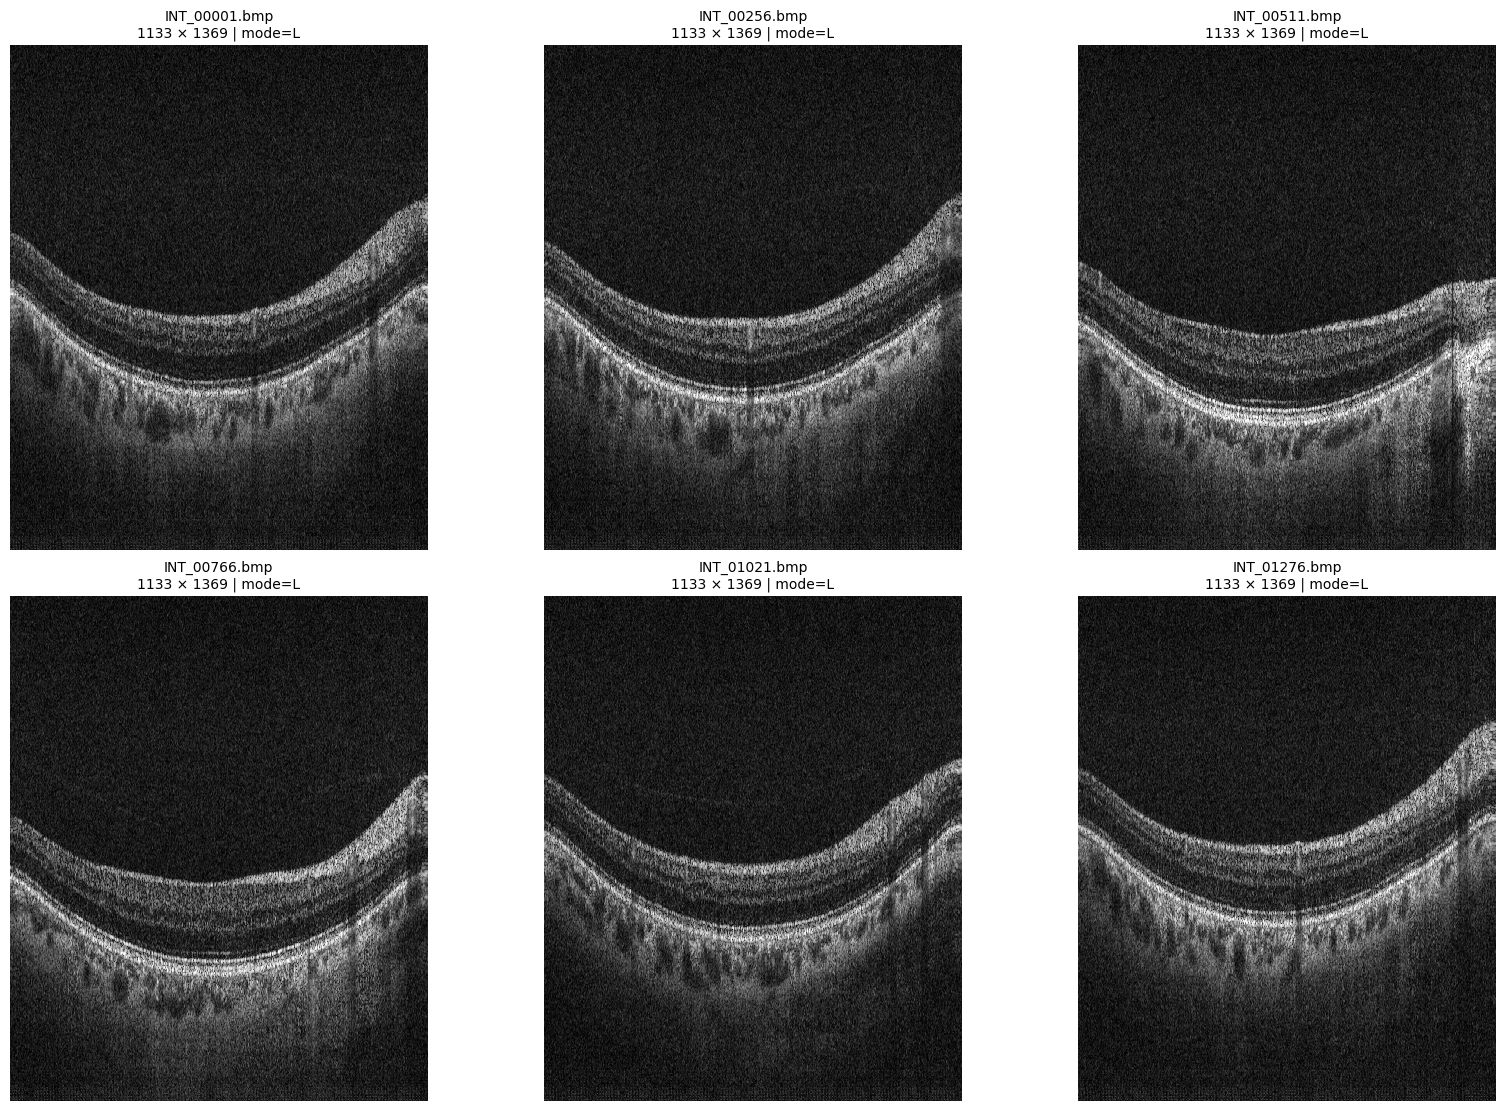

,file,width,height,original_mode,decoded_is_grayscale,decode_status
0,INT_00001.bmp,1133,1369,L,True,OK
1,INT_00256.bmp,1133,1369,L,True,OK
2,INT_00511.bmp,1133,1369,L,True,OK
3,INT_00766.bmp,1133,1369,L,True,OK
4,INT_01021.bmp,1133,1369,L,True,OK
5,INT_01276.bmp,1133,1369,L,True,OK


In [7]:
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. INT folder locate karo.
ROOT = Path.home() / "OCT-RTFL"
INT_DIR = ROOT / "raw_data/retina_dataset/INT"

if not INT_DIR.is_dir():
    raise FileNotFoundError(f"Folder nahi mila: {INT_DIR}")

# 2. BMP filenames collect karo.
int_files = sorted(
    path
    for path in INT_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() == ".bmp"
)

if not int_files:
    raise RuntimeError("INT folder mein BMP files nahi mili.")

print("Total INT BMP files:", len(int_files))

# 3. File list ke different positions se 6 examples select karo.
# Ye visual inspection sample hai, patient-wise sampling nahi.
indices = np.linspace(
    0, len(int_files) - 1,
    num=min(6, len(int_files)),
    dtype=int,
)

selected_files = [int_files[i] for i in indices]

# 4. Images display karo aur basic properties record karo.
rows = []
fig, axes = plt.subplots(
    2, 3, figsize=(16, 11),
    constrained_layout=True,
)
axes = axes.ravel()

for ax in axes:
    ax.axis("off")

for ax, path in zip(axes, selected_files):
    try:
        with Image.open(path) as image:
            original_mode = image.mode
            width, height = image.size

            # Palette ko properly decode karta hai.
            # Colored annotations hon toh unke colors bhi preserve honge.
            rgb = np.array(image.convert("RGB"))

        grayscale = bool(
            np.array_equal(rgb[:, :, 0], rgb[:, :, 1])
            and np.array_equal(rgb[:, :, 1], rgb[:, :, 2])
        )

        rows.append({
            "file": str(path.relative_to(INT_DIR)),
            "width": width,
            "height": height,
            "original_mode": original_mode,
            "decoded_is_grayscale": grayscale,
            "decode_status": "OK",
        })

        ax.imshow(rgb, interpolation="nearest")
        ax.set_title(
            f"{path.name}\n"
            f"{width} × {height} | mode={original_mode}",
            fontsize=10,
        )

    except Exception as error:
        rows.append({
            "file": str(path.relative_to(INT_DIR)),
            "decode_status": f"FAILED: {error}",
        })
        ax.set_title(f"{path.name}\nDecode failed")

plt.show()
display(pd.DataFrame(rows))

In [1]:
import sys
import platform
from importlib import metadata

print("Python version:", platform.python_version())
print("Python executable:", sys.executable)

packages = [
    "torch",
    "torchvision",
    "numpy",
    "Pillow",
    "transformers",
    "huggingface-hub",
    "timm",
    "safetensors",
    "sam2",
]

print("\nInstalled package versions:")
for package in packages:
    try:
        version = metadata.version(package)
    except metadata.PackageNotFoundError:
        version = "NOT INSTALLED"

    print(f"{package:18s} : {version}")

print("\nRead-only check complete.")
print("No packages installed or changed; no GPU computation started.")

Python version: 3.10.21
Python executable: /home/btech10862.24/miniconda3/envs/oct_nfl/bin/python

Installed package versions:
torch              : 2.5.1+cu121
torchvision        : 0.20.1+cu121
numpy              : 2.2.6
Pillow             : 12.3.0
transformers       : NOT INSTALLED
huggingface-hub    : 2.0.0
timm               : 1.0.22
safetensors        : 0.8.0
sam2               : NOT INSTALLED

Read-only check complete.
No packages installed or changed; no GPU computation started.
